# Linear Regression — from scratch + scikit-learn

**Goal:** predict a continuous target as `ŷ = Xβ` by minimizing squared error.

- Dataset: scikit-learn **Diabetes** (built-in, offline). Kaggle equivalent:
  *House Prices – Advanced Regression Techniques*.
- Structure: Intuition → Math → From scratch (Normal Equation + Gradient Descent)
  → scikit-learn + metrics (R², **Adjusted R²**, RMSE) → assumption checks → recap.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
np.random.seed(0)
print("libraries loaded")

libraries loaded


## 1. Intuition

Fit the straight line / hyperplane that is on average closest to all points, where
"closest" = smallest **sum of squared vertical residuals**. Each coefficient
`βⱼ` = how much `y` changes per unit increase in feature `xⱼ` (holding others fixed).

## 2. Math

Model: $\hat{y} = X\beta$ (X has a leading column of 1s for the intercept).

Loss (mean squared error): $J(\beta) = \frac{1}{n}\lVert y - X\beta \rVert^2$.

Setting the gradient to zero gives the **Normal Equation** (exact solution):
$$\beta = (X^\top X)^{-1} X^\top y$$

Gradient (used by gradient descent):
$$\nabla J = -\frac{2}{n} X^\top (y - X\beta)$$

OLS is also the **maximum-likelihood** estimate under Gaussian noise.

In [2]:
# ---- 3. FROM SCRATCH ----
data = load_diabetes()
X, y = data.data, data.target
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=0)

# standardize (helps gradient descent) and add bias column
scaler = StandardScaler().fit(X_tr)
X_tr_s, X_te_s = scaler.transform(X_tr), scaler.transform(X_te)
Xb_tr = np.c_[np.ones(len(X_tr_s)), X_tr_s]
Xb_te = np.c_[np.ones(len(X_te_s)), X_te_s]

# (a) Normal Equation
beta_ne = np.linalg.inv(Xb_tr.T @ Xb_tr) @ Xb_tr.T @ y_tr

# (b) Gradient Descent
def fit_gd(X, y, lr=0.1, epochs=50000):
    beta = np.zeros(X.shape[1]); n = len(y)
    for _ in range(epochs):
        grad = -(2/n) * X.T @ (y - X @ beta)
        beta -= lr * grad
    return beta
beta_gd = fit_gd(Xb_tr, y_tr)

print("intercept (NE vs GD):", round(beta_ne[0],3), round(beta_gd[0],3))
print("max |NE - GD| coef diff:", round(np.max(np.abs(beta_ne - beta_gd)), 4))

def r2(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred)**2)
    ss_tot = np.sum((y_true - y_true.mean())**2)
    return 1 - ss_res/ss_tot
print("from-scratch test R^2:", round(r2(y_te, Xb_te @ beta_ne), 4))

intercept (NE vs GD): 151.606 151.606
max |NE - GD| coef diff: 0.0
from-scratch test R^2: 0.3322


### What we just showed
Normal Equation and Gradient Descent converge to (nearly) the **same coefficients**
— two routes to the same OLS solution. Now the library version, and we confirm it
matches.

In [3]:
# ---- 4. SCIKIT-LEARN + METRICS ----
lr = LinearRegression().fit(X_tr_s, y_tr)
pred = lr.predict(X_te_s)

n, p = X_te_s.shape          # samples, num features
r2_val = r2_score(y_te, pred)
adj_r2 = 1 - (1 - r2_val) * (n - 1) / (n - p - 1)   # ADJUSTED R^2
rmse = mean_squared_error(y_te, pred) ** 0.5
mae = mean_absolute_error(y_te, pred)

print(f"R^2         : {r2_val:.4f}")
print(f"Adjusted R^2: {adj_r2:.4f}")
print(f"RMSE        : {rmse:.2f}")
print(f"MAE         : {mae:.2f}")
print("sklearn intercept vs from-scratch:", round(lr.intercept_,3), round(beta_ne[0],3))

R^2         : 0.3322
Adjusted R^2: 0.2466
RMSE        : 58.52
MAE         : 46.17
sklearn intercept vs from-scratch: 151.606 151.606


### R² vs Adjusted R² (the interview question)
`R²` never decreases as you add features. **Adjusted R²** subtracts a penalty for
the number of predictors `p`, so adding a useless feature can *lower* it — that's
why you compare models of different size with adjusted R², not R².

In [4]:
# Demonstrate: add 8 RANDOM noise features -> R^2 goes up, Adjusted R^2 should not
rng = np.random.RandomState(1)
noise_tr = rng.randn(len(X_tr_s), 8)
noise_te = rng.randn(len(X_te_s), 8)
Xn_tr = np.c_[X_tr_s, noise_tr]
Xn_te = np.c_[X_te_s, noise_te]
lr2 = LinearRegression().fit(Xn_tr, y_tr)
pred2 = lr2.predict(Xn_te)
r2b = r2_score(y_te, pred2)
p2 = Xn_te.shape[1]
adjb = 1 - (1 - r2b) * (n - 1) / (n - p2 - 1)
print(f"With 8 junk features -> R^2={r2b:.4f} (vs {r2_val:.4f}), Adjusted R^2={adjb:.4f} (vs {adj_r2:.4f})")
print("Note how Adjusted R^2 rewards the honest model.")

With 8 junk features -> R^2=0.2907 (vs 0.3322), Adjusted R^2=0.1083 (vs 0.2466)
Note how Adjusted R^2 rewards the honest model.


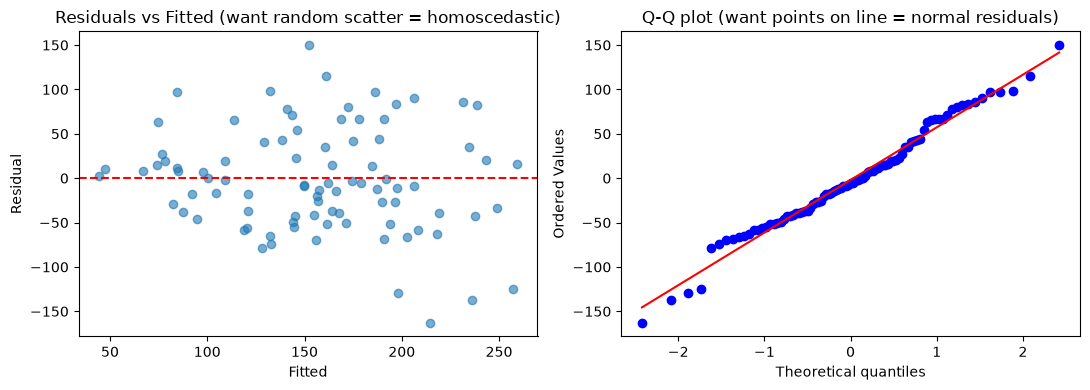

Max VIF (>5-10 = multicollinearity concern): 53.41


In [5]:
# ---- ASSUMPTION CHECKS ----
resid = y_te - pred
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(pred, resid, alpha=0.6); ax[0].axhline(0, color='r', ls='--')
ax[0].set_xlabel("Fitted"); ax[0].set_ylabel("Residual")
ax[0].set_title("Residuals vs Fitted (want random scatter = homoscedastic)")
from scipy import stats
stats.probplot(resid, plot=ax[1])
ax[1].set_title("Q-Q plot (want points on line = normal residuals)")
plt.tight_layout(); plt.show()

# Multicollinearity via VIF
from statsmodels.stats.outliers_influence import variance_inflation_factor
Xc = np.c_[np.ones(len(X_tr_s)), X_tr_s]
vifs = [variance_inflation_factor(Xc, i) for i in range(1, Xc.shape[1])]
print("Max VIF (>5-10 = multicollinearity concern):", round(max(vifs), 2))

## 5. Interview recap
- **R² vs Adjusted R²** — R² never decreases with more features; adjusted R²
  penalizes `p`, so use it to compare models of different size (we demonstrated it).
- **5 assumptions** — linearity, independent errors, homoscedasticity (residuals-vs-
  fitted plot), normal residuals (Q-Q plot), no multicollinearity (VIF).
- **Normal Equation vs Gradient Descent** — exact `(XᵀX)⁻¹Xᵀy` vs iterative; both
  reached the same β here.
- **Why squared error?** convex + differentiable + MLE under Gaussian noise.